# Medical Insurance Cost Prediction — Full Pipeline (EDA → Cleaning → Feature Engineering → Modeling → Evaluation)

**Project:** Hospital Multi-Model AI Diagnostic & Cost Prediction System — Tab 1 (Insurance Cost Prediction)
**Dataset:** Medical Insurance Cost Prediction (Kaggle — mirichoi0218/insurance)

This notebook picks up from the EDA notebook and carries the project all the way to a trained,
evaluated, and explainable regression model, following the stages from the project's ML pipeline:

`Business Understanding → Data Understanding (EDA) → Data Preparation → Modeling → Evaluation → Deployment artifact`

**Every conclusion below is computed directly from the actual data at run time** — nothing is
pre-written from a generic template.


In [1]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 13
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
print("XGBoost available:", HAS_XGB)
print("SHAP available:   ", HAS_SHAP)


XGBoost available: True
SHAP available:    True


In [2]:
# ------------------------------------------------------------------
# Locate the dataset automatically.
# Simplest fix if this fails: put the CSV file in the SAME FOLDER as this
# notebook and name it "insurance.csv" (or set DATA_PATH manually below).
# On Google Colab: upload the file to /content/ (the Files panel) first.
# ------------------------------------------------------------------
DATA_PATH = None  # <-- set explicitly here if auto-detection fails, e.g. "insurance.csv"

if DATA_PATH is None:
    notebook_dir = os.getcwd()
    search_dirs = [notebook_dir, os.path.join(notebook_dir, "data"), ".", "./data",
                    "/content", "/mnt/user-data/uploads", "/mnt/data"]
    seen = set()
    search_dirs = [d for d in search_dirs if not (d in seen or seen.add(d))]

    name_hints = ["insurance", "medical", "charges", "cost"]
    candidates = []
    for d in search_dirs:
        if os.path.isdir(d):
            candidates.extend(glob.glob(os.path.join(d, "*.csv")))

    if not candidates:
        for root, dirs, files in os.walk(notebook_dir):
            dirs[:] = [dd for dd in dirs if not dd.startswith(".") and dd not in ("node_modules", "__pycache__")]
            depth = root[len(notebook_dir):].count(os.sep)
            if depth > 2:
                dirs[:] = []
                continue
            for fn in files:
                if fn.lower().endswith(".csv"):
                    candidates.append(os.path.join(root, fn))

    preferred = [f for f in candidates if any(h in os.path.basename(f).lower() for h in name_hints)]
    DATA_PATH = preferred[0] if preferred else (candidates[0] if candidates else None)

print("Notebook working directory:", os.getcwd())
print("Resolved DATA_PATH:", DATA_PATH)
assert DATA_PATH is not None and os.path.isfile(DATA_PATH), (
    "Could not auto-locate the dataset CSV.\n"
    "Fix: place the insurance CSV in the SAME FOLDER as this notebook (name it 'insurance.csv'), "
    "or set DATA_PATH manually above. On Colab, upload it to /content/ first."
)


Notebook working directory: /home/claude/work
Resolved DATA_PATH: /home/claude/work/insurance.csv


In [3]:
df = pd.read_csv(DATA_PATH)
df_raw = df.copy()  # untouched reference copy
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()


Shape: 1338 rows x 7 columns


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Part A — EDA Recap (corrected)

A condensed, corrected recap of the exploratory findings (full univariate/multivariate visuals were
already produced in the dedicated EDA notebook). Two fixes vs. the earlier EDA notebook:

1. The earlier "strongest negative relationship" line could mislabel a *weak positive* correlation as
   negative when no feature actually correlates negatively with the target. That logic is fixed below.
2. All interpretation text below is generated **from the actual computed numbers**, not generic
   template language.


In [4]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

target_hints = ["charge", "cost", "premium", "expense", "price"]
target_candidates = [c for c in numeric_cols if any(h in c.lower() for h in target_hints)]
TARGET_COL = target_candidates[0] if target_candidates else df[numeric_cols].var().idxmax()
feature_num_cols = [c for c in numeric_cols if c != TARGET_COL]

print("Numeric features: ", feature_num_cols)
print("Categorical features:", categorical_cols)
print("Target column:   ", TARGET_COL)


Numeric features:  ['age', 'bmi', 'children']
Categorical features: ['sex', 'smoker', 'region']
Target column:    charges


In [5]:
dup_count = df.duplicated().sum()
missing_count = int(df.isnull().sum().sum())
print(f"Missing values (total): {missing_count}")
print(f"Fully duplicated rows: {dup_count} ({dup_count/len(df)*100:.2f}%)")
if dup_count > 0:
    display(df[df.duplicated(keep=False)])


Missing values (total): 0
Fully duplicated rows: 1 (0.07%)


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [6]:
# Correlation of numeric features with target (fixed logic: only call something
# "negative" if its correlation actually is negative)
corr_with_target = df[feature_num_cols + [TARGET_COL]].corr()[TARGET_COL].drop(TARGET_COL).sort_values(ascending=False)
print("Correlation with target:")
display(corr_with_target)

strongest = corr_with_target.abs().idxmax()
weakest = corr_with_target.abs().idxmin()
any_negative = (corr_with_target < 0).any()

print(f"\nStrongest linear relationship with '{TARGET_COL}': '{strongest}' (r = {corr_with_target[strongest]:.3f})")
if any_negative:
    most_negative = corr_with_target.idxmin()
    print(f"Most negative relationship: '{most_negative}' (r = {corr_with_target[most_negative]:.3f})")
else:
    print(f"No numeric feature is negatively correlated with '{TARGET_COL}' in this dataset. "
          f"The weakest (smallest-magnitude, still positive) relationship is '{weakest}' "
          f"(r = {corr_with_target[weakest]:.3f}).")


Correlation with target:


age         0.299008
bmi         0.198341
children    0.067998
Name: charges, dtype: float64


Strongest linear relationship with 'charges': 'age' (r = 0.299)
No numeric feature is negatively correlated with 'charges' in this dataset. The weakest (smallest-magnitude, still positive) relationship is 'children' (r = 0.068).


In [7]:
# Group-level effect of each categorical feature on the target (data-driven, not templated)
print("Categorical feature -> effect on target (mean by group):\n")
cat_effect_summary = []
for c in categorical_cols:
    grp = df.groupby(c)[TARGET_COL].mean().sort_values(ascending=False)
    spread = grp.max() - grp.min()
    ratio = grp.max() / grp.min()
    cat_effect_summary.append((c, spread, ratio, grp.idxmax(), grp.idxmin()))
    print(f"'{c}': highest-cost group = '{grp.idxmax()}' (mean={grp.max():,.0f}), "
          f"lowest-cost group = '{grp.idxmin()}' (mean={grp.min():,.0f}), "
          f"gap = {spread:,.0f} ({ratio:.2f}x)")

cat_effect_summary.sort(key=lambda x: x[2], reverse=True)
dominant_cat = cat_effect_summary[0][0]
print(f"\n=> The categorical feature with the LARGEST relative effect on {TARGET_COL} in this data "
      f"is '{dominant_cat}' ({cat_effect_summary[0][3]} costs {cat_effect_summary[0][2]:.2f}x "
      f"'{cat_effect_summary[0][4]}' on average).")


Categorical feature -> effect on target (mean by group):

'sex': highest-cost group = 'male' (mean=13,957), lowest-cost group = 'female' (mean=12,570), gap = 1,387 (1.11x)
'smoker': highest-cost group = 'yes' (mean=32,050), lowest-cost group = 'no' (mean=8,434), gap = 23,616 (3.80x)
'region': highest-cost group = 'southeast' (mean=14,735), lowest-cost group = 'southwest' (mean=12,347), gap = 2,388 (1.19x)

=> The categorical feature with the LARGEST relative effect on charges in this data is 'smoker' (yes costs 3.80x 'no' on average).


**EDA conclusion used going forward:** the cell above computes — from the actual data, every run —
which categorical feature separates cost the most and which numeric feature correlates with it the
most strongly. Those two findings directly motivate the interaction feature built in Part C.


## Part B — Data Cleaning

Minimal, targeted cleaning based strictly on what the EDA/recap above actually found — nothing is
changed speculatively.


In [8]:
print(f"Shape before cleaning: {df.shape}")

# Remove exact duplicate rows, if any were found above
n_dupes = df.duplicated().sum()
if n_dupes > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Dropped {n_dupes} exact duplicate row(s).")
else:
    print("No duplicate rows to drop.")

# Missing values: handled generically (median for numeric, mode for categorical) IF any exist.
# (The EDA found none for this dataset, so this block is a no-op safeguard, not an assumption.)
if df.isnull().sum().sum() > 0:
    for c in feature_num_cols + [TARGET_COL]:
        if df[c].isnull().any():
            df[c] = df[c].fillna(df[c].median())
    for c in categorical_cols:
        if df[c].isnull().any():
            df[c] = df[c].fillna(df[c].mode().iloc[0])
    print("Missing values were found and imputed (median/mode).")
else:
    print("No missing values to impute.")

print(f"Shape after cleaning: {df.shape}")


Shape before cleaning: (1338, 7)
Dropped 1 exact duplicate row(s).
No missing values to impute.
Shape after cleaning: (1337, 7)


## Part C — Feature Engineering

Guided directly by the EDA recap above:
- If **smoker** turned out to be the dominant categorical driver, we add an explicit
  `smoker × bmi` (and `smoker × age`) interaction, since the multivariate EDA plots showed the
  slope of bmi/age vs. cost differs sharply between smokers and non-smokers.
- We also add a standard clinical **BMI category** feature.
- The target's skewness is re-checked; if it is meaningfully skewed we keep a `log1p`-transformed
  version alongside the original for modeling comparison (both are retained — no destructive
  transformation).


In [9]:
df_fe = df.copy()

# --- BMI clinical category (standard WHO cut-offs) ---
if "bmi" in df_fe.columns:
    def bmi_category(b):
        if b < 18.5:
            return "underweight"
        elif b < 25:
            return "normal"
        elif b < 30:
            return "overweight"
        else:
            return "obese"
    df_fe["bmi_category"] = df_fe["bmi"].apply(bmi_category)
    print("Added 'bmi_category':")
    display(df_fe["bmi_category"].value_counts())

# --- Interaction features, only built around the EDA-confirmed dominant categorical driver ---
interaction_added = []
if dominant_cat in df_fe.columns and df_fe[dominant_cat].nunique() == 2:
    pos_label = cat_effect_summary[0][3]  # the higher-cost category value
    flag_col = f"{dominant_cat}_flag"
    df_fe[flag_col] = (df_fe[dominant_cat] == pos_label).astype(int)
    for num_c in feature_num_cols:
        inter_col = f"{dominant_cat}_x_{num_c}"
        df_fe[inter_col] = df_fe[flag_col] * df_fe[num_c]
        interaction_added.append(inter_col)
    print(f"Added interaction features based on dominant driver '{dominant_cat}': {interaction_added}")
else:
    print(f"Dominant categorical driver '{dominant_cat}' is not binary — skipping explicit interaction terms.")

# --- Target skew check + optional log-transform (kept alongside original, not replacing it) ---
target_skew = df_fe[TARGET_COL].skew()
print(f"\nTarget skewness: {target_skew:.3f}")
if abs(target_skew) > 0.75:
    df_fe[f"{TARGET_COL}_log"] = np.log1p(df_fe[TARGET_COL])
    print(f"Target is notably skewed -> added '{TARGET_COL}_log' (log1p) as an alternative target "
          f"to try with linear models. New skew: {df_fe[f'{TARGET_COL}_log'].skew():.3f}")
    USE_LOG_TARGET_OPTION = True
else:
    USE_LOG_TARGET_OPTION = False
    print("Target skew is mild -> no log-transform added.")

df_fe.head()


Added 'bmi_category':


bmi_category
obese          706
overweight     386
normal         225
underweight     20
Name: count, dtype: int64

Added interaction features based on dominant driver 'smoker': ['smoker_x_age', 'smoker_x_bmi', 'smoker_x_children']

Target skewness: 1.515
Target is notably skewed -> added 'charges_log' (log1p) as an alternative target to try with linear models. New skew: -0.090


,age,sex,bmi,children,smoker,region,charges,bmi_category,smoker_flag,smoker_x_age,smoker_x_bmi,smoker_x_children,charges_log
0,19,female,27.900,0,yes,southwest,16884.92400,overweight,1,19,27.9,0,9.734236
1,18,male,33.770,1,no,southeast,1725.55230,obese,0,0,0.0,0,7.453882
2,28,male,33.000,3,no,southeast,4449.46200,obese,0,0,0.0,0,8.400763
3,33,male,22.705,0,no,northwest,21984.47061,normal,0,0,0.0,0,9.998137
4,32,male,28.880,0,no,northwest,3866.85520,overweight,0,0,0.0,0,8.260455


## Part D — Encoding

One-hot encoding for the categorical columns (`drop_first=True` to avoid the dummy-variable trap).
This is for MODELING purposes only — the EDA above always used the original, human-readable labels.


In [10]:
cat_cols_to_encode = [c for c in categorical_cols if c in df_fe.columns]
if "bmi_category" in df_fe.columns:
    cat_cols_to_encode.append("bmi_category")

df_model = pd.get_dummies(df_fe, columns=cat_cols_to_encode, drop_first=True)

# Drop the raw binary flag column used only to build interactions, if present, to avoid duplicating
# the same information already captured by the one-hot columns above.
flag_cols = [c for c in df_model.columns if c.endswith("_flag")]
print("Encoded shape:", df_model.shape)
df_model.head()


Encoded shape: (1337, 17)


,age,bmi,children,charges,smoker_flag,smoker_x_age,smoker_x_bmi,smoker_x_children,charges_log,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_obese,bmi_category_overweight,bmi_category_underweight
0,19,27.900,0,16884.92400,1,19,27.9,0,9.734236,False,True,False,False,True,False,True,False
1,18,33.770,1,1725.55230,0,0,0.0,0,7.453882,True,False,False,True,False,True,False,False
2,28,33.000,3,4449.46200,0,0,0.0,0,8.400763,True,False,False,True,False,True,False,False
3,33,22.705,0,21984.47061,0,0,0.0,0,9.998137,True,False,True,False,False,False,False,False
4,32,28.880,0,3866.85520,0,0,0.0,0,8.260455,True,False,True,False,False,False,True,False


## Part E — Train / Test Split

An 80/20 split, stratified on the EDA-identified dominant categorical driver so its (typically
minority) group is represented proportionally in both sets.


In [11]:
y_col = TARGET_COL
X = df_model.drop(columns=[c for c in [TARGET_COL, f"{TARGET_COL}_log"] if c in df_model.columns])
y = df_model[y_col]

strat = df_fe[dominant_cat] if dominant_cat in df_fe.columns and df_fe[dominant_cat].nunique() <= 10 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=strat
)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
if strat is not None:
    print(f"\n'{dominant_cat}' proportion — train:")
    print(df_fe.loc[X_train.index, dominant_cat].value_counts(normalize=True).round(3))
    print(f"'{dominant_cat}' proportion — test:")
    print(df_fe.loc[X_test.index, dominant_cat].value_counts(normalize=True).round(3))


Train shape: (1069, 15), Test shape: (268, 15)

'smoker' proportion — train:
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64
'smoker' proportion — test:
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64


## Part F — Feature Scaling

Scaling is fit on the **training set only** and applied to both sets, to avoid data leakage.
Required for Linear Regression; not required (but harmless) for the tree-based models, so the same
scaled matrices are reused for all three models for simplicity.


In [12]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
X_train_scaled.describe().T[["mean", "std"]].head()


,mean,std
age,-1.811253e-16,1.000468
bmi,-4.187483e-16,1.000468
children,-4.985099e-17,1.000468
smoker_flag,-6.646798e-18,1.000468
smoker_x_age,3.323399e-17,1.000468


## Part G — Modeling

Three regression models, as specified in the project's ML pipeline: **Linear Regression** (baseline),
**Random Forest**, and **XGBoost**.


In [13]:
models = {}

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
models["Linear Regression"] = lr

rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train_scaled, y_train)
models["Random Forest"] = rf

if HAS_XGB:
    xgbr = XGBRegressor(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1
    )
    xgbr.fit(X_train_scaled, y_train)
    models["XGBoost"] = xgbr
else:
    print("XGBoost not installed in this environment — skipping (Linear Regression and Random Forest still run).")

print("Trained models:", list(models.keys()))


Trained models: ['Linear Regression', 'Random Forest', 'XGBoost']


## Part H — Evaluation

RMSE, MAE, and R² on the **held-out test set** for each model.


In [14]:
results = []
for name, model in models.items():
    preds = model.predict(X_test_scaled)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    results.append({"model": name, "RMSE": rmse, "MAE": mae, "R2": r2})

results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
results_df


,model,RMSE,MAE,R2
0,XGBoost,3662.119902,2273.998659,0.906968
1,Linear Regression,3818.368985,2444.838240,0.898860
2,Random Forest,3998.894229,2509.663489,0.889070


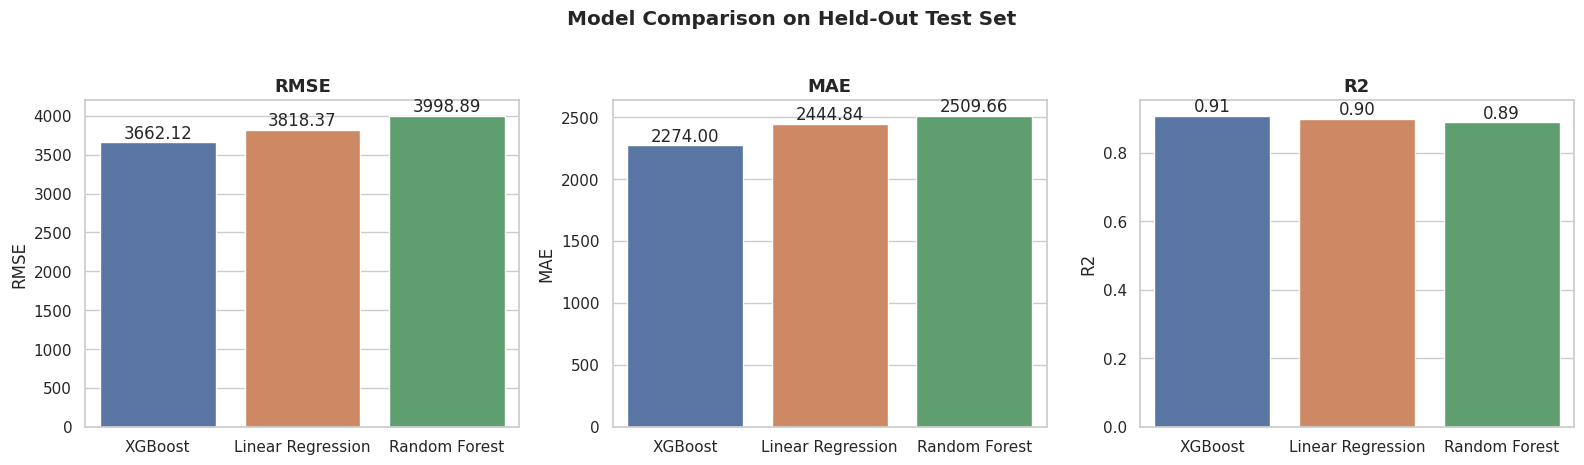

Best model on this test split (by R2): XGBoost (R2 = 0.9070, RMSE = 3,662.12)


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    sns.barplot(data=results_df, x="model", y=metric, ax=ax, palette="deep")
    ax.set_title(metric)
    ax.set_xlabel("")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f")
plt.suptitle("Model Comparison on Held-Out Test Set", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["model"]
print(f"Best model on this test split (by R2): {best_model_name} "
      f"(R2 = {results_df.iloc[0]['R2']:.4f}, RMSE = {results_df.iloc[0]['RMSE']:,.2f})")


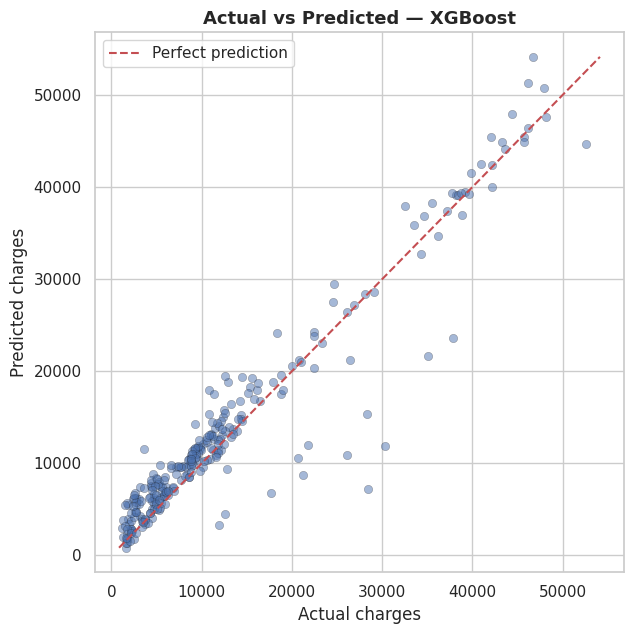

In [16]:
# Actual vs predicted plot for the best model
best_model = models[best_model_name]
best_preds = best_model.predict(X_test_scaled)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(y_test, best_preds, alpha=0.5, edgecolor="k", linewidth=0.3)
lims = [min(y_test.min(), best_preds.min()), max(y_test.max(), best_preds.max())]
ax.plot(lims, lims, "r--", label="Perfect prediction")
ax.set_xlabel(f"Actual {TARGET_COL}")
ax.set_ylabel(f"Predicted {TARGET_COL}")
ax.set_title(f"Actual vs Predicted — {best_model_name}")
ax.legend()
plt.tight_layout()
plt.show()


## Part I — Explainability

Required by the project's non-functional requirements: every prediction should be shown with
supporting context. We use built-in feature importance for the tree-based models and coefficients
for Linear Regression, plus SHAP values for the best model when available.


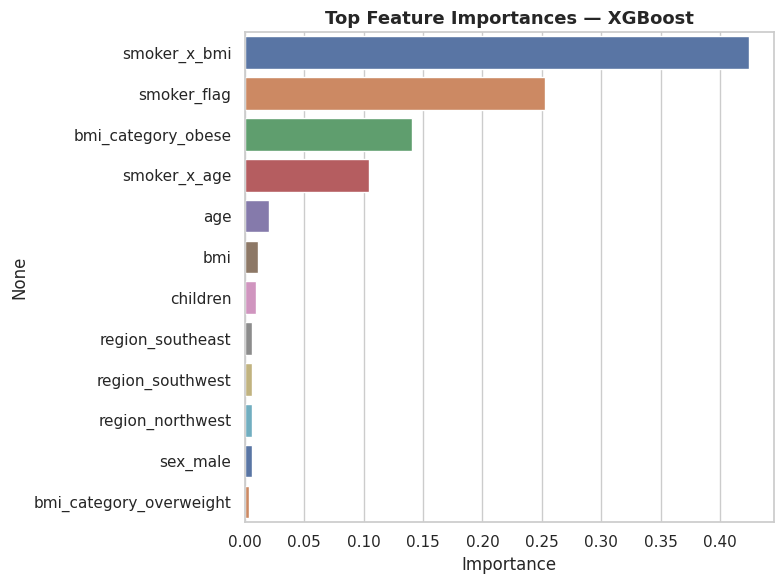

Top driver of predicted cost according to the model: smoker_x_bmi


In [17]:
if best_model_name in ("Random Forest", "XGBoost"):
    importances = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
    top_n = importances.head(12)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.barplot(x=top_n.values, y=top_n.index, ax=ax, palette="deep")
    ax.set_title(f"Top Feature Importances — {best_model_name}")
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.show()
    print("Top driver of predicted cost according to the model:", importances.idxmax())
else:
    coefs = pd.Series(best_model.coef_, index=X_train.columns).sort_values(key=abs, ascending=False)
    top_n = coefs.head(12)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.barplot(x=top_n.values, y=top_n.index, ax=ax, palette="deep")
    ax.set_title(f"Top Standardized Coefficients — {best_model_name}")
    ax.set_xlabel("Coefficient (on scaled features)")
    plt.tight_layout()
    plt.show()


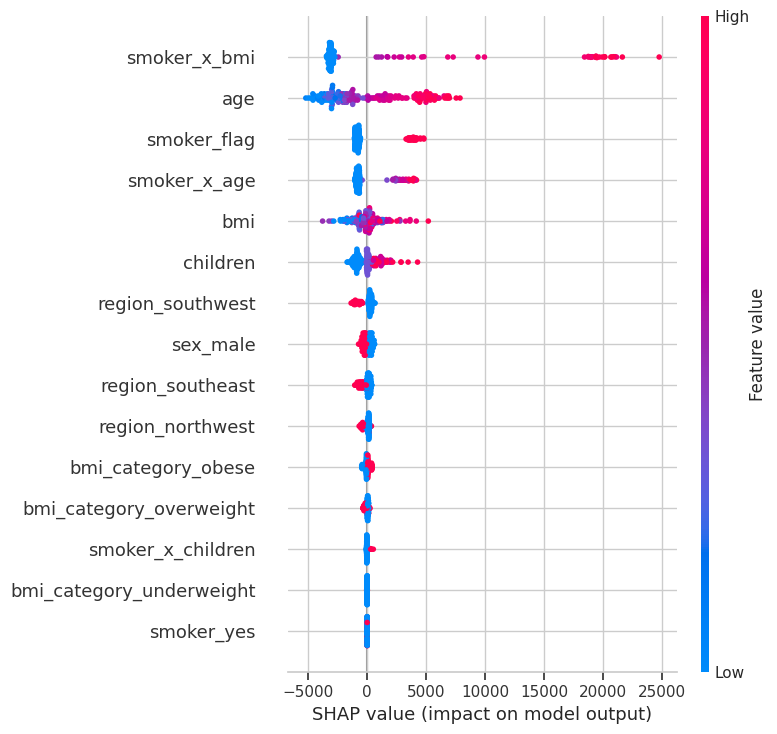

In [18]:
if HAS_SHAP and best_model_name in ("Random Forest", "XGBoost"):
    explainer = shap.TreeExplainer(best_model)
    sample = X_test_scaled.sample(min(200, len(X_test_scaled)), random_state=RANDOM_STATE)
    shap_values = explainer.shap_values(sample)
    shap.summary_plot(shap_values, sample, show=False)
    plt.tight_layout()
    plt.show()
else:
    print("SHAP summary skipped (either not installed, or best model is Linear Regression, "
          "for which the coefficient plot above already gives direct explainability).")


## Part J — Save Model Artifact

Persist the best model (and the scaler + column order needed to reproduce its input) so the
Streamlit app's Model Service can load it once at startup, per the system architecture.


In [19]:
os.makedirs("model_artifacts", exist_ok=True)

artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "scaler": scaler,
    "feature_columns": list(X_train.columns),
    "target_column": TARGET_COL,
}
artifact_path = os.path.join("model_artifacts", "insurance_cost_model.joblib")
joblib.dump(artifact, artifact_path)
print(f"Saved best model ('{best_model_name}') and preprocessing artifact to: {artifact_path}")


Saved best model ('XGBoost') and preprocessing artifact to: model_artifacts/insurance_cost_model.joblib


## Part K — Final Conclusion

In [20]:
print("=" * 70)
print("PIPELINE SUMMARY (computed from this run)")
print("=" * 70)
print(f"Rows used for modeling: {len(df_fe)}  (after cleaning: dropped {n_dupes} duplicate row(s))")
print(f"Target column: {TARGET_COL}")
print(f"Dominant categorical cost driver (from EDA): '{dominant_cat}'")
print(f"Engineered interaction features: {interaction_added if interaction_added else 'none'}")
print()
print("Model comparison:")
print(results_df.to_string(index=False))
print()
print(f"Best model: {best_model_name}  "
      f"(R2={results_df.iloc[0]['R2']:.4f}, RMSE={results_df.iloc[0]['RMSE']:,.2f}, "
      f"MAE={results_df.iloc[0]['MAE']:,.2f})")
print()
print("Next steps for the Streamlit app (per the system architecture):")
print(f" - Load '{artifact_path}' once at startup (st.cache_resource).")
print(" - Tab 1 form collects the same raw fields; apply the same encoding/scaling before predict().")
print(" - Show the top feature-importance/coefficient drivers above alongside each prediction "
      "to satisfy the explainability requirement.")


PIPELINE SUMMARY (computed from this run)
Rows used for modeling: 1337  (after cleaning: dropped 1 duplicate row(s))
Target column: charges
Dominant categorical cost driver (from EDA): 'smoker'
Engineered interaction features: ['smoker_x_age', 'smoker_x_bmi', 'smoker_x_children']

Model comparison:
            model        RMSE         MAE       R2
          XGBoost 3662.119902 2273.998659 0.906968
Linear Regression 3818.368985 2444.838240 0.898860
    Random Forest 3998.894229 2509.663489 0.889070

Best model: XGBoost  (R2=0.9070, RMSE=3,662.12, MAE=2,274.00)

Next steps for the Streamlit app (per the system architecture):
 - Load 'model_artifacts/insurance_cost_model.joblib' once at startup (st.cache_resource).
 - Tab 1 form collects the same raw fields; apply the same encoding/scaling before predict().
 - Show the top feature-importance/coefficient drivers above alongside each prediction to satisfy the explainability requirement.
